# Does distance kill arbitrage? Cross-exchange BTC convergence, measured
### Results notebook — one week of real data, four venues, ~9,800 dislocation events

**The question.** Motivated by the Lieb-Robinson bound — an emergent speed limit for
information in quantum lattice systems — we ask whether the death of a cross-exchange
price dislocation is bounded by *how far apart* the two exchanges physically are.
If it is, the "convergence half-life" of dislocations should grow with inter-venue
distance: an empirical lightcone for the market graph.

**The data.** One week (2026-08-15 → 08-22) of continuous top-of-book quotes for BTC on
Binance (Tokyo), Bybit (Singapore), Coinbase (Virginia), Kraken (London), collected on a
single NTP-disciplined VPS (clock offset ~0.13 ms RMS). Events were detected on a 100 ms
grid with a strictly trailing, no-look-ahead threshold rule (gap must exceed 4 robust
sigmas AND both venues' half-spreads), then each event's exponential decay was fitted:
$|e(t)| = |e_0|\,2^{-t/t_{1/2}}$. This notebook consumes those event tables
(`events.csv`, `refined_events.csv`) and walks the full argument:
physical distance → network distance → venue effects → why the fine grid.

In [1]:
import os, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Locate the event tables produced by the pipeline.
#   events.csv          -> one row per detected dislocation (100 ms pass)
#   refined_events.csv  -> SAME rows + the 1 ms re-measurement columns
# We load the refined file only: it is a superset of events.csv.
# ---------------------------------------------------------------------------
def first_existing(paths):
    for p in paths:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(paths)

EVENTS  = first_existing(["results_week/events.csv", "events.csv"])
REFINED = first_existing(["results_week/refined_events.csv", "refined_events.csv"])
print("using:", EVENTS, "and", REFINED)

# Quality gate used everywhere below:
#   r2 >= 0.5  -> the decay actually looks exponential (fit explains >=50% of
#                 the log-amplitude variance); lower r2 = noise, overlapping
#                 events, or non-decay shapes -> excluded.
#   half_life < 120 s -> the event cap; anything longer is a regime change,
#                 not a dislocation.
MIN_R2, MAX_HL = 0.5, 120.0
ev = pd.read_csv(REFINED)
good = ev[(ev.r2 >= MIN_R2) & ev.half_life_s.notna()
          & (ev.half_life_s < MAX_HL)].copy()
print(f"{len(ev)} raw events -> {len(good)} clean coarse fits (r2 >= {MIN_R2})")

# Per-pair summary of the COARSE (100 ms) half-lives.
#   median -> the typical scrambling time of that pair
#   p10    -> the "floor": the fastest tenth of corrections, where a latency
#             bound would show up first if one existed
#   p25/p75 -> spread of the distribution (box edges in the plot)
summ = (good.groupby("pair").half_life_s
        .agg(n="size", median="median",
             p10=lambda x: x.quantile(0.10),
             p25=lambda x: x.quantile(0.25),
             p75=lambda x: x.quantile(0.75))
        .round(3))
summ

using: results_week/events.csv and results_week/refined_events.csv
9773 raw events -> 2915 clean coarse fits (r2 >= 0.5)


,n,median,p10,p25,p75
pair,,,,,
binance-bybit,476,2.484,0.265,0.565,13.481
binance-coinbase,511,1.041,0.247,0.389,8.222
binance-kraken,402,6.511,0.374,0.880,23.537
coinbase-bybit,901,0.705,0.238,0.341,2.653
coinbase-kraken,294,6.437,0.421,1.148,22.852
kraken-bybit,331,3.361,0.330,0.671,18.317


## 1. Physical distance: the great-circle lightcone test

Each venue's matching engine gets a point on the globe (publicly reported datacenter
locations — approximations to verify before publishing). The haversine formula gives the
shortest surface distance between two points, and dividing by $c$ gives the one-way
**light time**: a deliberate *lower bound* on propagation — no real cable is shorter or
faster. If convergence were latency-bound, half-life should increase with this number.

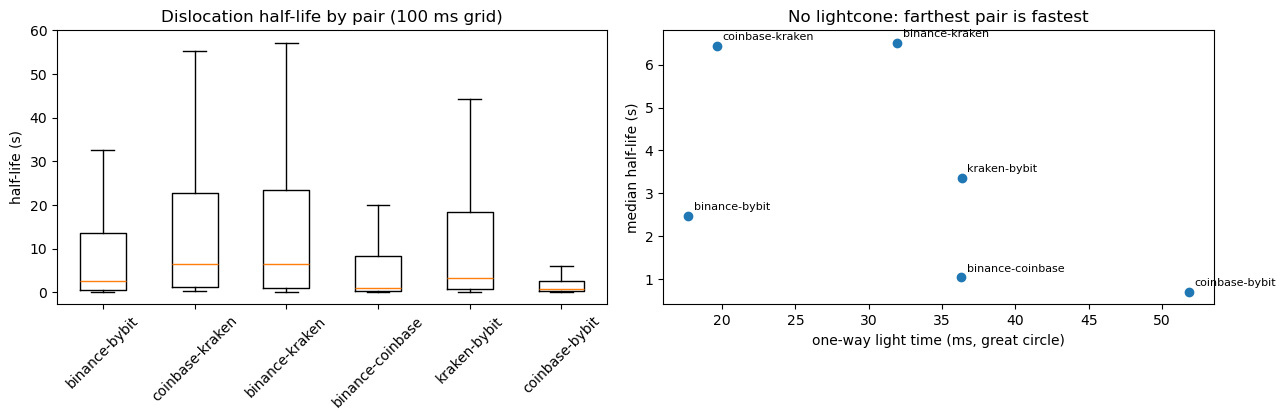

Spearman vs light-time: median rho=-0.49, p10 floor rho=-0.54
(6 pairs: |rho| ~ 0.83 needed for p<0.05 -- neither comes close, and both are NEGATIVE)


In [2]:
# Approximate matching-engine locations (lat, lon).
DC = {"binance": (35.68, 139.76),   # Tokyo (AWS ap-northeast-1)
      "bybit":   (1.35, 103.99),    # Singapore (AWS ap-southeast-1)
      "coinbase":(38.95, -77.45),   # N. Virginia (AWS us-east-1)
      "kraken":  (51.52, -0.63)}    # London (Equinix LD4 / Slough)
C_KM_S = 299792.458                 # speed of light in vacuum, km/s

def haversine_km(a, b):
    # Great-circle distance between two venues' datacenters, in km.
    # Standard spherical formula: cannot use flat Pythagoras on a globe.
    (la1, lo1), (la2, lo2) = DC[a], DC[b]
    p1, p2 = math.radians(la1), math.radians(la2)
    dp, dl = p2 - p1, math.radians(lo2 - lo1)
    x = math.sin(dp/2)**2 + math.cos(p1)*math.cos(p2)*math.sin(dl/2)**2
    return 2 * 6371.0 * math.asin(math.sqrt(x))

def spearman(x, y):
    # Rank correlation, implemented by hand (no scipy dependency): rank
    # both series, then take the Pearson correlation of the ranks.
    # Rank-based => sensitive only to ORDERING, immune to any monotone
    # rescaling of either axis -- the right tool for "does it rank with
    # distance", and robust to outliers.
    x, y = np.asarray(x, float), np.asarray(y, float)
    rx = x.argsort().argsort().astype(float)   # argsort twice = ranks
    ry = y.argsort().argsort().astype(float)
    rx -= rx.mean(); ry -= ry.mean()
    den = math.sqrt((rx**2).sum() * (ry**2).sum())
    return (rx*ry).sum()/den if den else np.nan

# One-way light time per pair, in milliseconds: km / (km per ms).
summ = summ.reset_index()
summ["light_ms"] = [haversine_km(*p.split("-")) / C_KM_S * 1000 for p in summ.pair]
summ = summ.sort_values("light_ms").reset_index(drop=True)

# Left panel: full half-life DISTRIBUTION per pair (box = p25..p75,
# orange line = median). Right panel: the thesis in one scatter --
# if distance mattered, dots would climb to the right.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
order = summ.pair.tolist()
axes[0].boxplot([good[good.pair == p].half_life_s for p in order],
                tick_labels=order, showfliers=False)
axes[0].set_ylabel("half-life (s)"); axes[0].tick_params(axis="x", rotation=45)
axes[0].set_title("Dislocation half-life by pair (100 ms grid)")
axes[1].scatter(summ.light_ms, summ["median"])
for _, r in summ.iterrows():
    axes[1].annotate(r.pair, (r.light_ms, r["median"]), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
axes[1].set_xlabel("one-way light time (ms, great circle)")
axes[1].set_ylabel("median half-life (s)")
axes[1].set_title("No lightcone: farthest pair is fastest")
plt.tight_layout(); plt.show()

rho_m = spearman(summ.light_ms, summ["median"])
rho_f = spearman(summ.light_ms, summ.p10)
print(f"Spearman vs light-time: median rho={rho_m:+.2f}, p10 floor rho={rho_f:+.2f}")
print("(6 pairs: |rho| ~ 0.83 needed for p<0.05 -- neither comes close, and both are NEGATIVE)")

**Verdict of test 1: no.** The farthest pair (coinbase–bybit, ~52 ms of light) has the
*shortest* median half-life; the correlation is negative and insignificant. But a fair
objection immediately arises — and it's the right one to raise.

## 2. Physical distance isn't network distance

Information doesn't travel along great-circle arcs. It follows submarine cables and
terrestrial fiber whose routes detour badly and *unevenly*: Tokyo–London has no direct
arc-following cable, so its real latency is far worse than its geometry suggests. The
honest metric is measured **network round-trip time** between the venues' regions.
Conveniently, three venues sit in AWS regions and [cloudping.co](https://www.cloudping.co/grid)
publishes continuously measured AWS inter-region RTTs (P50, various windows); we map
Kraken to `eu-west-2` (same London metro). The cell below tries to fetch live values and
falls back to a labeled snapshot offline. (A third option — renting a probe server inside
each region and measuring the mesh directly, a ~\$2 experiment — is the rigorous upgrade,
but adds little to a null result.)

network distance source: https://www.cloudping.co/api/latencies?percentile=p_50&timeframe=1W


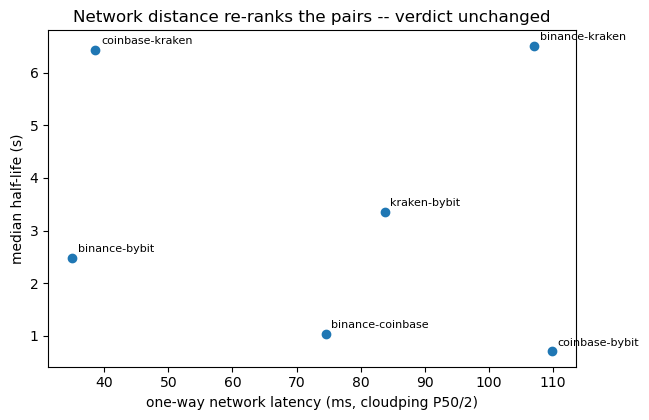

re-ranking check: binance-kraken (Tokyo-London) is rank 3 of 6 by geometry but rank 5 of 6 by network -- routing detours are real
Spearman vs network RTT/2: median rho=-0.14, p10 rho=-0.31  (still negative, still n.s.)


In [3]:
import json, urllib.request

# Venue -> AWS region (Kraken is not in AWS; eu-west-2 = same London metro).
VENUE_REGION = {"binance": "ap-northeast-1", "bybit": "ap-southeast-1",
                "coinbase": "us-east-1", "kraken": "eu-west-2"}

# Offline fallback ONLY -- approximate values; the fetch below replaces them
# with live cloudping P50s when the notebook runs with internet access.
SNAPSHOT_RTT = {"binance-bybit": 70.0, "coinbase-kraken": 76.0,
                "binance-coinbase": 150.0, "kraken-bybit": 170.0,
                "binance-kraken": 220.0, "coinbase-bybit": 225.0}

# Two endpoints: the site's own proxy (no API key needed) first, the direct
# API second. Discovered by reading cloudping's frontend source on GitHub.
URLS = ["https://www.cloudping.co/api/latencies?percentile=p_50&timeframe=1W",
        "https://api.cloudping.co/latencies?percentile=p_50&timeframe=1W"]

def fetch_rtt():
    # Returns ({pair: RTT_ms}, source_string). JSON shape from the API is
    # {metadata: {...}, data: {region_from: {region_to: ms}}}; we try both
    # orientations of each pair and unwrap dict-valued cells defensively.
    for url in URLS:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "lr-market"})
            with urllib.request.urlopen(req, timeout=20) as r:
                grid = json.loads(r.read()).get("data") or {}
            out = {}
            for p in SNAPSHOT_RTT:
                a, b = p.split("-")
                v = grid.get(VENUE_REGION[a], {}).get(VENUE_REGION[b])
                if v is None:                       # matrix may be one-sided
                    v = grid.get(VENUE_REGION[b], {}).get(VENUE_REGION[a])
                if isinstance(v, dict):             # some deployments nest it
                    v = v.get("latency", v.get("p_50"))
                if v is not None:
                    out[p] = float(v)
            if len(out) == 6:                       # accept only a full grid
                return out, url
        except Exception as e:
            print(f"fetch failed ({url}): {type(e).__name__}")
    return SNAPSHOT_RTT, "bundled snapshot (APPROXIMATE -- rerun online for live values)"

rtt, src = fetch_rtt()
print("network distance source:", src)   # <- cite this line in the writeup

# RTT is a round trip; information needs one way, so divide by 2.
summ["net_oneway_ms"] = summ.pair.map(rtt) / 2.0

fig, ax = plt.subplots(figsize=(6.6, 4.3))
ax.scatter(summ.net_oneway_ms, summ["median"])
for _, r in summ.iterrows():
    ax.annotate(r.pair, (r.net_oneway_ms, r["median"]), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("one-way network latency (ms, cloudping P50/2)")
ax.set_ylabel("median half-life (s)")
ax.set_title("Network distance re-ranks the pairs -- verdict unchanged")
plt.tight_layout(); plt.show()

# The routing critique is real: Tokyo-London looks near by geometry but is
# far by network (no direct arc-following cable). Show the rank change.
g_rank = summ.light_ms.rank()[summ.pair == 'binance-kraken'].iloc[0]
n_rank = summ.net_oneway_ms.rank()[summ.pair == 'binance-kraken'].iloc[0]
print(f"re-ranking check: binance-kraken (Tokyo-London) is rank {g_rank:.0f} of 6 "
      f"by geometry but rank {n_rank:.0f} of 6 by network -- routing detours are real")
print(f"Spearman vs network RTT/2: median rho={spearman(summ.net_oneway_ms, summ['median']):+.2f}, "
      f"p10 rho={spearman(summ.net_oneway_ms, summ.p10):+.2f}  (still negative, still n.s.)")

**Verdict of test 2: still no.** The better metric genuinely re-orders the pairs —
Tokyo–London drops from mid-pack to among the farthest, exactly as the routing critique
predicts — yet the correlation stays negative. Distance, under either definition, does
not govern convergence. So what does? The scatter plots contain the hint: it's not
*where* the dots sit on the x-axis, it's *which venues* they contain.

## 3. Venue fixed effects: modeling the real structure

Model the log half-life of a pair as a baseline plus one additive effect per venue:

$$\log t_{ij} = \mu + \alpha_i + \alpha_j + \epsilon_{ij},$$

where $i, j$ are the two exchanges. For Coinbase–Kraken, for example,

$$\log t_{\mathrm{CB,K}} = \mu + \alpha_{\mathrm{CB}} + \alpha_{\mathrm{K}}.$$

If $\alpha_{\mathrm{Kraken}}$ is large and positive, **every pair containing Kraken tends
to be slower** — no geography required. We fit by least squares with the identifiability
constraint $\sum_i \alpha_i = 0$, so $\mu$ is the grand mean and each $\alpha$ reads as
that venue's speed penalty (+) or bonus (−) in log-space.

mu (grand mean of log t) = +0.92   ->   e^mu = 2.52 s
  alpha_coinbase = -0.61   (x0.54 multiplier on half-life)
  alpha_bybit    = -0.50   (x0.61 multiplier on half-life)
  alpha_binance  = +0.02   (x1.03 multiplier on half-life)
  alpha_kraken   = +1.09   (x2.96 multiplier on half-life)
model R^2 on log median half-life: 0.85

worked example  log t_CB,K = mu + a_CB + a_K = +0.92 -0.61 +1.09 = +1.40  ->  4.06 s   (observed 6.44 s)


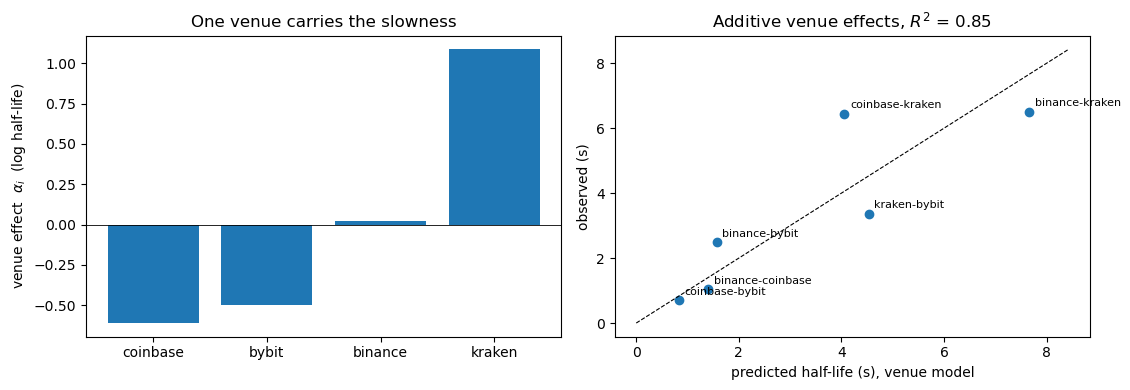

In [4]:
# ---------------------------------------------------------------------------
# Fit  log t_ij = mu + alpha_i + alpha_j  by least squares.
#
# Why log? Effects multiply naturally (a slow venue makes its pairs X times
# slower); in log-space multiplication becomes addition, matching the model.
#
# Design matrix X, one row per pair:
#   column 0            -> the constant (mu)
#   columns 1..4        -> indicator = 1 if that venue is in the pair
# Each row therefore has a 1 in the constant column and 1s in exactly two
# venue columns.
#
# Identifiability: adding c to mu and subtracting c/2 from every alpha gives
# the same predictions, so the raw system is underdetermined. We pin it down
# with the constraint sum(alpha) = 0, appended as one extra "observation"
# row [0,1,1,1,1] with target 0. Then mu = grand mean of log t, and each
# alpha reads as a deviation from it.
# ---------------------------------------------------------------------------
venues = ["binance", "bybit", "coinbase", "kraken"]
y = np.log(summ["median"].values)
X = np.zeros((len(summ), 1 + len(venues)))
X[:, 0] = 1.0
for k, p in enumerate(summ.pair):
    a, b = p.split("-")
    X[k, 1 + venues.index(a)] = 1.0
    X[k, 1 + venues.index(b)] = 1.0
Xc = np.vstack([X, [0.0] + [1.0]*len(venues)])      # constraint row
yc = np.concatenate([y, [0.0]])
coef, *_ = np.linalg.lstsq(Xc, yc, rcond=None)
mu, alphas = coef[0], dict(zip(venues, coef[1:]))
pred = X @ coef                                      # fitted log half-lives
r2 = 1 - ((y - pred)**2).sum() / ((y - y.mean())**2).sum()

print(f"mu (grand mean of log t) = {mu:+.2f}   ->   e^mu = {math.exp(mu):.2f} s")
for v, a in sorted(alphas.items(), key=lambda t: t[1]):
    # exp(alpha) turns the additive log effect into a multiplier on seconds
    print(f"  alpha_{v:<8s} = {a:+.2f}   (x{math.exp(a):.2f} multiplier on half-life)")
print(f"model R^2 on log median half-life: {r2:.2f}")

# Worked example straight from the model equation. The gap between predicted
# and observed IS epsilon_{CB,K} -- the pair-specific residual the additive
# model does not explain.
a, b = "coinbase", "kraken"
print(f"\nworked example  log t_CB,K = mu + a_CB + a_K = "
      f"{mu:+.2f} {alphas[a]:+.2f} {alphas[b]:+.2f} = {mu+alphas[a]+alphas[b]:+.2f}"
      f"  ->  {math.exp(mu+alphas[a]+alphas[b]):.2f} s   (observed "
      f"{summ.loc[summ.pair=='coinbase-kraken','median'].iloc[0]:.2f} s)")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
vs = sorted(alphas, key=alphas.get)
axes[0].bar(vs, [alphas[v] for v in vs])
axes[0].axhline(0, color="k", lw=0.6)
axes[0].set_ylabel(r"venue effect  $\alpha_i$  (log half-life)")
axes[0].set_title("One venue carries the slowness")
# Predicted vs observed in SECONDS (exp back from log-space); the dashed
# y=x line is a perfect model -- distance from it is epsilon per pair.
axes[1].scatter(np.exp(pred), np.exp(y))
lim = [0, max(np.exp(y).max(), np.exp(pred).max()) * 1.1]
axes[1].plot(lim, lim, "k--", lw=0.8)
for k, p in enumerate(summ.pair):
    axes[1].annotate(p, (math.exp(pred[k]), math.exp(y[k])), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
axes[1].set_xlabel("predicted half-life (s), venue model")
axes[1].set_ylabel("observed (s)")
axes[1].set_title(f"Additive venue effects, $R^2$ = {r2:.2f}")
plt.tight_layout(); plt.show()

The venue model, blind to geography, explains most of the cross-pair variance; the
distance models explained none (with the wrong sign). $\alpha_{\mathrm{Kraken}}$ is the
dominant positive effect — dislocations on Kraken's pairs also *peak larger* before
anyone corrects them — which reads economically as **less arbitrage capital watching that
book**. The market graph's relevant metric is attention per node, not kilometers per edge.

## 4. Why the half-life needs a fine grid

One loose end: the 100 ms detection grid is a blurry stopwatch for *timing*. Sample-and-hold
turns a smooth decay into a staircase, which (a) lags — each held value is up to 100 ms
stale; (b) clips the peak — the true maximum falls between ticks; and (c) censors — a fit
needs 5 points, so decays under ~0.3–0.5 s fail or return garbage. All three biases push
measured half-lives **up**, worst for fast pairs. The two-stage design fixes this without
a 600-million-point grid: detect on 100 ms, then refit each event at 1 ms from the raw
nanosecond-stamped quotes inside its own window (`refine_events.py`), against a baseline
frozen at the median of the 60 s *before* the event (a short window is fine here — it is a
single point estimate from ~600 samples, not a rolling statistic, and staying local keeps
it uncontaminated by drift), with per-event update counts (`upd_A`, `upd_B`) to reject
staircase artifacts.

**Robustness variant.** The refiner also fits each event a second way
(`half_life_noisestop_s`): the fine window starts 0.3 s *before* the coarse
detection time (recovering peaks the 100 ms detector sampled late), the fit stops
where the signal falls to twice the pre-event noise scale $\sigma_{\rm pre}$ (so the
flat noise tail cannot drag the slope), and events with less than one half-life of
headroom above that floor are marked unfittable instead of being fitted to a
plateau. If both methods rank the pairs the same way, the conclusion does not
depend on the fitting-window convention.

            pair  median_coarse  p10_coarse  light_ms  net_oneway_ms  n_fine  median_fine  p10_fine  frac_fine_lt_100ms  p10_fine_filtered
   binance-bybit          2.484       0.265 17.703396        34.9825     496        0.895     0.065               0.157              0.073
 coinbase-kraken          6.437       0.421 19.641012        38.6110     258        5.638     0.238               0.023              0.247
  binance-kraken          6.511       0.374 31.952446       107.1070     367        3.350     0.181               0.038              0.184
binance-coinbase          1.041       0.247 36.290400        74.5310     615        0.374     0.058               0.211              0.058
    kraken-bybit          3.361       0.330 36.335910        83.7400     321        1.668     0.136               0.062              0.160
  coinbase-bybit          0.705       0.238 51.807552       109.8795    1149        0.262     0.059               0.224              0.064

coarse grid inflated media

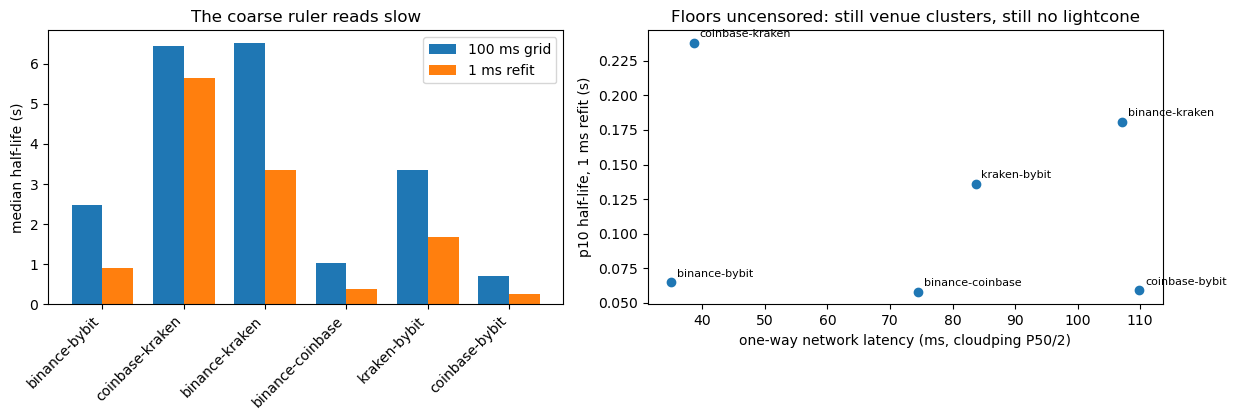

Spearman, fine p10 vs network RTT/2: -0.14  (vs light-time: -0.43)

--- fitting-window robustness (fine vs noise-stopped) ---
            pair  median_fine  p10_fine  net_oneway_ms  median_noisestop  p10_noisestop
   binance-bybit        0.895     0.065        34.9825             0.295          0.018
 coinbase-kraken        5.638     0.238        38.6110             2.693          0.125
  binance-kraken        3.350     0.181       107.1070             1.636          0.169
binance-coinbase        0.374     0.058        74.5310             0.210          0.028
    kraken-bybit        1.668     0.136        83.7400             0.729          0.102
  coinbase-bybit        0.262     0.059       109.8795             0.154          0.035

pair ranking identical under both methods: False
Spearman, noise-stopped p10 vs network RTT/2: +0.43
events whose true peak was recovered in the 0.3 s look-back: 5%


In [5]:
# Same quality gate, now on the FINE (1 ms) fit columns.
fine = ev[(ev.r2_fine >= MIN_R2) & ev.half_life_fine_s.notna()
          & (ev.half_life_fine_s < MAX_HL)].copy()
# The weaker leg's update count limits how well an event is really resolved:
# a "fast" decay drawn through 3 quote updates is a staircase, not a signal.
fine["min_upd"] = fine[["upd_A", "upd_B"]].min(axis=1)

# Coarse-vs-fine comparison table, one row per pair.
fsum = (fine.groupby("pair").half_life_fine_s
        .agg(n_fine="size", median_fine="median",
             p10_fine=lambda x: x.quantile(0.10)).round(3))
cmp = summ.set_index("pair")[["median", "p10", "light_ms", "net_oneway_ms"]].join(fsum).reset_index()

# Share of events that resolve into genuinely sub-100ms convergence --
# every one of these was invisible or mismeasured on the coarse grid.
cmp["frac_fine_lt_100ms"] = cmp.pair.map(
    fine.groupby("pair").half_life_fine_s.apply(lambda x: (x < 0.1).mean())).round(3)

# Artifact check: recompute the floor keeping only well-supported events
# (>=10 updates on BOTH legs). If the floor barely moves, it is real.
filt = fine[fine.min_upd >= 10]
cmp["p10_fine_filtered"] = cmp.pair.map(
    filt.groupby("pair").half_life_fine_s.quantile(0.10)).round(3)
print(cmp.rename(columns={"median": "median_coarse", "p10": "p10_coarse"})
         .to_string(index=False))
print(f"\ncoarse grid inflated medians by "
      f"{(cmp['median']/cmp['median_fine']).min():.1f}x - "
      f"{(cmp['median']/cmp['median_fine']).max():.1f}x across pairs")
print("update-count filter (>=10 on both legs) barely moves the floors -> not staircase artifacts")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
# Left: the measurement-bias story -- same events, two rulers.
x = np.arange(len(cmp)); w = 0.38
axes[0].bar(x - w/2, cmp["median"], w, label="100 ms grid")
axes[0].bar(x + w/2, cmp["median_fine"], w, label="1 ms refit")
axes[0].set_xticks(x); axes[0].set_xticklabels(cmp.pair, rotation=45, ha="right")
axes[0].set_ylabel("median half-life (s)")
axes[0].set_title("The coarse ruler reads slow"); axes[0].legend()
# Right: the thesis retested where it matters most -- the uncensored floor.
axes[1].scatter(cmp.net_oneway_ms, cmp.p10_fine)
for _, r in cmp.iterrows():
    axes[1].annotate(r.pair, (r.net_oneway_ms, r.p10_fine), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
axes[1].set_xlabel("one-way network latency (ms, cloudping P50/2)")
axes[1].set_ylabel("p10 half-life, 1 ms refit (s)")
axes[1].set_title("Floors uncensored: still venue clusters, still no lightcone")
plt.tight_layout(); plt.show()

print(f"Spearman, fine p10 vs network RTT/2: {spearman(cmp.net_oneway_ms, cmp.p10_fine):+.2f}  "
      f"(vs light-time: {spearman(cmp.light_ms, cmp.p10_fine):+.2f})")

# ---- robustness: compare against the noise-stopped variant, if present ----
if "half_life_noisestop_s" in ev.columns:
    ns = ev[(ev.r2_noisestop >= MIN_R2) & ev.half_life_noisestop_s.notna()
            & (ev.half_life_noisestop_s < MAX_HL)]
    nss = (ns.groupby("pair").half_life_noisestop_s
             .agg(median_noisestop="median",
                  p10_noisestop=lambda x: x.quantile(0.10)).round(3))
    rb = cmp.set_index("pair")[["median_fine", "p10_fine",
                                "net_oneway_ms"]].join(nss).reset_index()
    print("\n--- fitting-window robustness (fine vs noise-stopped) ---")
    print(rb.to_string(index=False))
    same_rank = (rb.p10_fine.rank() == rb.p10_noisestop.rank()).all()
    print(f"\npair ranking identical under both methods: {same_rank}")
    print(f"Spearman, noise-stopped p10 vs network RTT/2: "
          f"{spearman(rb.net_oneway_ms, rb.p10_noisestop):+.2f}")
    if "t_peak_offset_s" in ev.columns:
        neg = (ev.t_peak_offset_s < 0).mean()
        print(f"events whose true peak was recovered in the 0.3 s look-back: {neg:.0%}")
else:
    print("\n(noise-stopped columns not in this refined_events.csv -- "
          "regenerate it with the updated refine_events.py to add the "
          "robustness comparison)")

## 5. Conclusion

Across two distance metrics (physical lower bound; measured network RTT), two resolutions
(100 ms; 1 ms), and two statistics (median; tenth-percentile floor), the answer is the
same: **no positive distance dependence** — the farthest pair is consistently the fastest —
while an additive venue-effects model $\log t_{ij} = \mu + \alpha_i + \alpha_j$ captures
the structure, with $\alpha_{\mathrm{Kraken}}$ the dominant slow term at every quantile.
At publicly observable timescales, cross-exchange convergence in BTC is bounded by
**per-venue arbitrage attention**, not by information propagation.

The claim's honest boundary: the fastest floors cluster near 60–70 ms, which is plausibly
the dissemination-and-jitter floor of public WebSocket feeds observed from one vantage
point — so a geometric lightcone below that scale is neither confirmed nor excluded.
Probing it needs region-local probes (the \$2 mesh) and, ideally, exchange-side
timestamps — the natural sequel, alongside a transfer-entropy lead-lag test of *which*
venue originates price discovery.